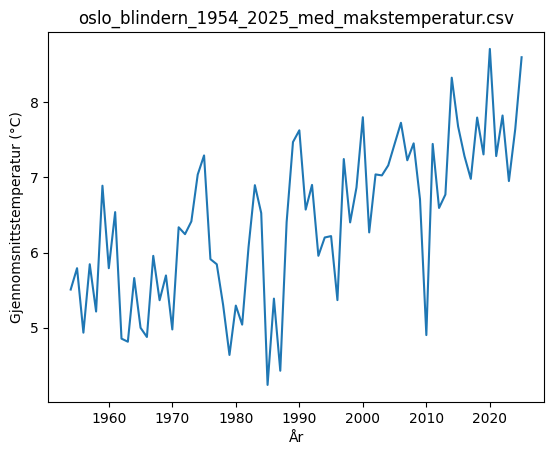

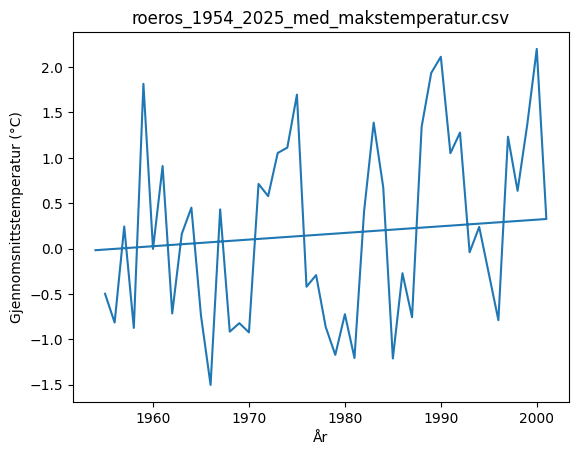

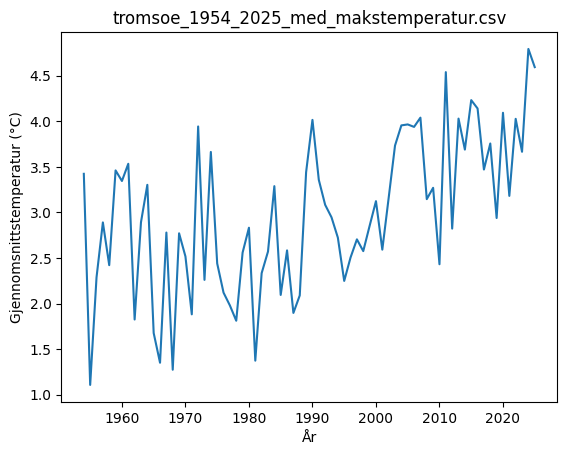

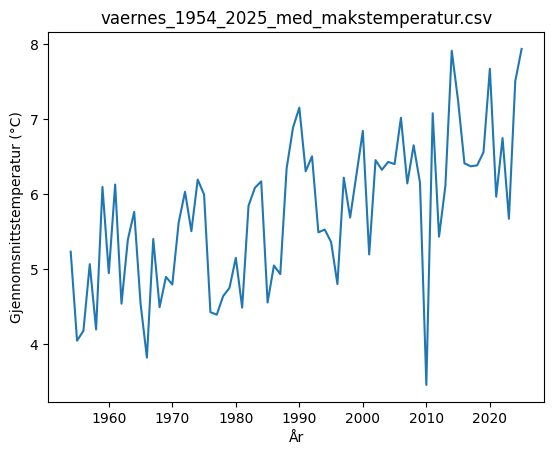

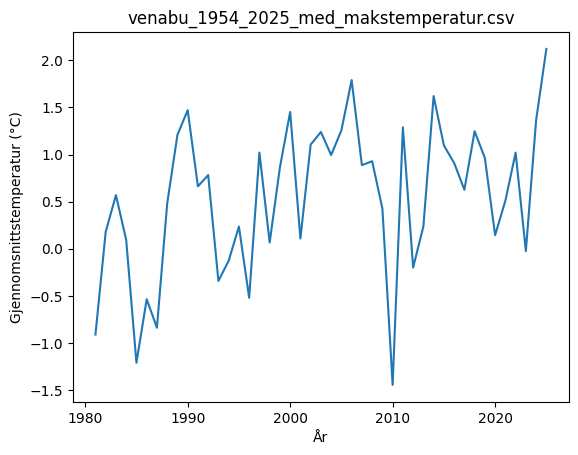

In [15]:
import csv
import matplotlib.pyplot as plt

filer = [
    "oslo_blindern_1954_2025_med_makstemperatur.csv",
    "roeros_1954_2025_med_makstemperatur.csv",
    "tromsoe_1954_2025_med_makstemperatur.csv",
    "vaernes_1954_2025_med_makstemperatur.csv",
    "venabu_1954_2025_med_makstemperatur.csv"
]

for filnavn in filer:
    data = {}

    with open(filnavn, encoding="utf-8") as fil:
        leser = csv.DictReader(fil, delimiter=";")

        for rad in leser:
            dato = rad["Tid(norsk normaltid)"]
            temp = rad["Middeltemperatur (døgn)"]

            if dato == "" or temp == "" or temp == "-":
                continue

            år = int(dato[-4:])
            temp = float(temp.replace(",", "."))

            if år not in data:
                data[år] = []

            data[år].append(temp)

    år_liste = []
    temperatur_liste = []

    for år in data:
        if len(data[år]) >= 300:
            år_liste.append(år)
            temperatur_liste.append(sum(data[år]) / len(data[år]))

    plt.figure()
    plt.plot(år_liste, temperatur_liste)

    plt.title(filnavn)
    plt.xlabel("År")
    plt.ylabel("Gjennomsnittstemperatur (°C)")
    plt.show()